# Study 9 fit with the per-feature ZOIB linking function

Detailed plots of the study-9 fit produced by `run_parameter_estimation.py study9-zoib`
(preregistered data, raw ratings), read from `results/study9-fit-zoib/`. **Read-only: nothing is refit.**

- θ = (ls, μ₀, σ, speaker β) inferred with VBMC (Laplace over coherence), linking profiled at every θ;
- linking: each feature has two ZOIB components (kind-linked / not kind-linked), each with its own
  P(0), P(100) and single-peaked Beta (`linking.py`);
- null: the same model with the length scale pinned flat (ls = 10, distance-blind).

For comparison, the original fit with the free Beta-mixture linking is read from `results/study9-fit/`.

1. Posterior over θ (full vs null)
2. Predicted vs empirical mean ratings
3. The coherence field
4. The linking components of each feature
5. Per-condition mixtures against the data
6. What the linking fixes vs what coherence moves

In [1]:
import os
os.environ.setdefault("JAX_ENABLE_X64", "1")

import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import plot_style
plot_style.use_lexend()          # Lexend everywhere (DejaVu Sans fills in σ/β)
from matplotlib.lines import Line2D
import jax.numpy as jnp
from scipy.stats import beta as sbeta

import inference as inf
import linking as lk

ZDIR, ODIR = os.path.join('results', 'study9-fit-zoib'), os.path.join('results', 'study9-fit')
geom = inf.load_geometry()
features, trait, J = geom['test_feature_names'], geom['test_trait'], geom['J']
CONDS = list(inf.CONDITIONS)
raw, _ = inf.load_responses('../../data/study9_prereg.csv', clip_interior=False)
K = {c: np.round(np.asarray(raw[c]) * 100).astype(int) for c in CONDS}
emp = {c: np.asarray(raw[c]).mean(0) for c in CONDS}

def load_post(path):
    z = np.load(path, allow_pickle=True)
    return {k: z[k] for k in ('ls_samples', 'mu0_samples', 'sigma_samples', 'beta_samples')} | json.loads(str(z['meta']))

POST = {'full (fitted ls)': load_post(os.path.join(ZDIR, 'posterior.npz')),
        'null (ls pinned)': load_post(os.path.join(ZDIR, 'posterior-null.npz'))}
zl = np.load(os.path.join(ZDIR, 'fitted-link-zoib.npz'), allow_pickle=True)
assert [str(f) for f in zl['feature_names']] == features
LS, MU, SIG, BETA = [float(v) for v in zl['theta']]
p = lk.params_to_numpy(lk.unpack(jnp.asarray(zl['link_theta'])))
pred = pd.read_csv(os.path.join(ZDIR, 'predictions.csv'))
pred_old = pd.read_csv(os.path.join(ODIR, 'predictions.csv'))
pz1 = {c: pred[pred.key == c].set_index('feature').loc[features, 'pz1_prior'].values for c in CONDS}
print(f"posterior median (full): ls={LS:.3f} mu_0={MU:+.3f} sigma={SIG:.3f} speaker beta={BETA:.3f}")

COND_COLOR = {'physical': '#2a78d6', 'diet': '#eb6834', 'personality': '#1baf7a', 'heterogeneous': '#eda100'}
FIT_COLOR = {'full (fitted ls)': '#2a78d6', 'null (ls pinned)': '#eb6834'}
CLS_COLOR = {'kl': '#2a78d6', 'nkl': '#eb6834'}
TEXT_1, TEXT_2, MUTED, GRID = '#0b0b0b', '#52514e', '#8a8984', '#e6e5e1'
TRAITS = ['diet', 'personality', 'physical']
plt.rcParams.update({
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.edgecolor': MUTED, 'axes.labelcolor': TEXT_2, 'xtick.color': TEXT_2, 'ytick.color': TEXT_2,
    'axes.titlesize': 10, 'axes.labelsize': 9, 'xtick.labelsize': 8, 'ytick.labelsize': 8,
    'legend.fontsize': 8, 'legend.frameon': False,
})
def grid_y(ax):
    ax.grid(axis='y', color=GRID, lw=0.6); ax.set_axisbelow(True)
def grid_xy(ax):
    ax.grid(color=GRID, lw=0.6); ax.set_axisbelow(True)

posterior median (full): ls=0.344 mu_0=+1.293 sigma=0.522 speaker beta=25.931


## 1. Posterior over θ

Marginal posteriors from VBMC for the full model and the null. Dashed lines = the edges of the VBMC box.
**Speaker β's upper edge is 30**: mass piled against it means the posterior is being cut off by the box,
not by the data. ELBOs are comparable between these two fits (same ZOIB likelihood), not with the
original free-linking fits.

In [2]:
rows = []
for name, f in POST.items():
    for k, lab in [('ls_samples', 'ls'), ('mu0_samples', 'mu_0'), ('sigma_samples', 'sigma'), ('beta_samples', 'speaker beta')]:
        q = np.percentile(f[k], [5, 50, 95])
        rows.append({'fit': name, 'param': lab, '5%': q[0], 'median': q[1], '95%': q[2]})
tbl = pd.DataFrame(rows).pivot(index='param', columns='fit', values=['5%', 'median', '95%']).round(3)
print({n: f"ELBO {f['elbo']:.1f} ({f['convergence_status']}, {f['func_count']} evals)" for n, f in POST.items()})
print(f"ELBO full − null = {POST['full (fitted ls)']['elbo'] - POST['null (ls pinned)']['elbo']:+.1f}")
tbl

{'full (fitted ls)': 'ELBO -1724.9 (probable, 195 evals)', 'null (ls pinned)': 'ELBO -1731.8 (probable, 180 evals)'}
ELBO full − null = +6.9


5%                            median  \
fit          full (fitted ls) null (ls pinned) full (fitted ls)   
param                                                             
ls                      0.186           10.000            0.344   
mu_0                    0.748            0.708            1.293   
sigma                   0.314            0.185            0.522   
speaker beta           18.317           15.227           25.931   

                                           95%                   
fit          null (ls pinned) full (fitted ls) null (ls pinned)  
param                                                            
ls                     10.000            0.727           10.000  
mu_0                    1.480            1.657            1.767  
sigma                   0.429            0.874            1.225  
speaker beta           22.801           29.440           29.023

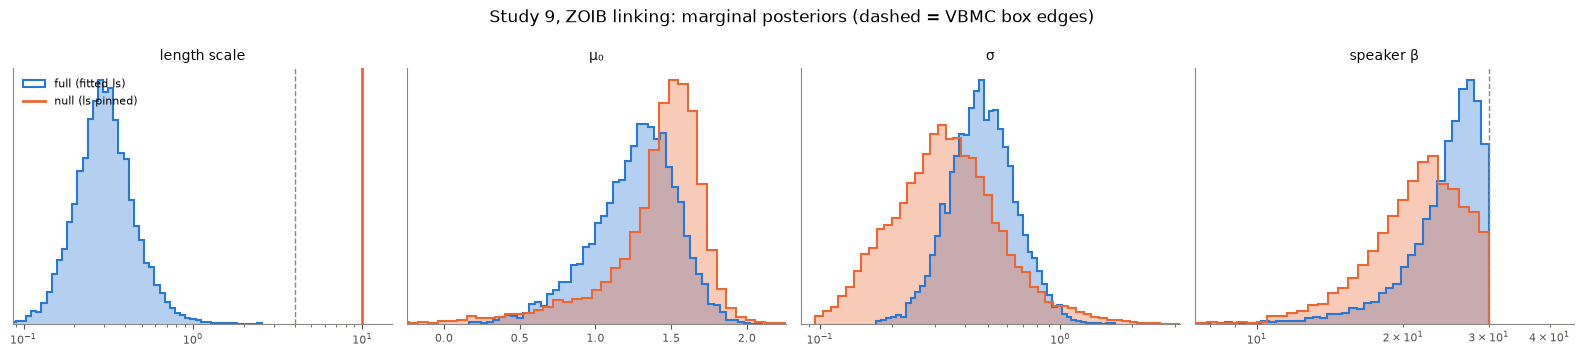

In [3]:
BOX = {'ls_samples': (np.exp(inf.LB_B[0]), np.exp(inf.UB_B[0])), 'mu0_samples': (inf.LB_B[1], inf.UB_B[1]),
       'sigma_samples': (np.exp(inf.LB_B[2]), np.exp(inf.UB_B[2])), 'beta_samples': (np.exp(inf.LB_B[3]), np.exp(inf.UB_B[3]))}
LOG = {'ls_samples': True, 'mu0_samples': False, 'sigma_samples': True, 'beta_samples': True}
fig, axes = plt.subplots(1, 4, figsize=(16, 3.6))
for ax, (k, lab) in zip(axes, [('ls_samples', 'length scale'), ('mu0_samples', 'μ₀'), ('sigma_samples', 'σ'),
                               ('beta_samples', 'speaker β')]):
    for name, f in POST.items():
        x = f[k]
        if np.ptp(x) == 0:
            ax.axvline(x[0], color=FIT_COLOR[name], lw=2, label=name)
            continue
        bins = np.geomspace(x.min(), x.max(), 50) if LOG[k] else np.linspace(x.min(), x.max(), 50)
        ax.hist(x, bins=bins, density=True, histtype='stepfilled', alpha=0.35, color=FIT_COLOR[name])
        ax.hist(x, bins=bins, density=True, histtype='step', lw=1.5, color=FIT_COLOR[name], label=name)
    for edge in BOX[k]:
        ax.axvline(edge, color=MUTED, lw=1, ls='--')
    if LOG[k]:
        ax.set_xscale('log')
    lo = min(np.percentile(f[k], 0.5) for f in POST.values()); hi = max(np.percentile(f[k], 99.5) for f in POST.values())
    ax.set_xlim(lo / 1.5 if LOG[k] else lo - 0.3, max(hi * 1.5, BOX[k][1] * 1.1) if k == 'beta_samples' else (hi * 1.5 if LOG[k] else hi + 0.3))
    ax.set_title(lab, color=TEXT_1); ax.set_yticks([]); grid_y(ax)
axes[0].legend(loc='upper left')
fig.suptitle('Study 9, ZOIB linking: marginal posteriors (dashed = VBMC box edges)', fontsize=12)
fig.tight_layout(); plt.show()

## 2. Predicted vs empirical mean ratings

`pred_prior`: the mean rating the model predicts in each condition × feature cell from the training
statements alone (ratings-free coherence). R² is split into between-feature (each feature's level) and
within-feature (each feature's condition differences, the part only the coherence field can explain).
Compared with the original free-linking fit and with memorizing each feature's mean.

In [4]:
r2 = lambda a, e: 1 - np.sum((e - a) ** 2) / np.sum((e - e.mean()) ** 2)
def mats(d, col='pred_prior'):
    P = d.pivot(index='key', columns='feature', values=col).loc[CONDS, features].values
    E = d.pivot(index='key', columns='feature', values='empirical_mean').loc[CONDS, features].values
    return P, E
def summary(name, P, E):
    Pb, Eb = P.mean(0), E.mean(0)
    return {'model': name, 'R2 overall': r2(P.ravel(), E.ravel()), 'R2 between': r2(Pb, Eb),
            'R2 within': r2((P - Pb).ravel(), (E - Eb).ravel()),
            'r within': np.corrcoef((P - Pb).ravel(), (E - Eb).ravel())[0, 1] if np.ptp(P - Pb) > 0 else np.nan}
Pz, E = mats(pred); Po, _ = mats(pred_old)
pd.DataFrame([summary('ZOIB linking (study9-fit-zoib)', Pz, E), summary('free linking (study9-fit)', Po, E),
              summary('memorize: feature mean', np.tile(E.mean(0), (len(CONDS), 1)), E)]).set_index('model').round(3)

,R2 overall,R2 between,R2 within,r within
model,,,,
ZOIB linking (study9-fit-zoib),0.776,0.997,0.042,0.343
free linking (study9-fit),0.705,0.915,0.011,0.347
memorize: feature mean,0.768,1.000,0.000,NaN


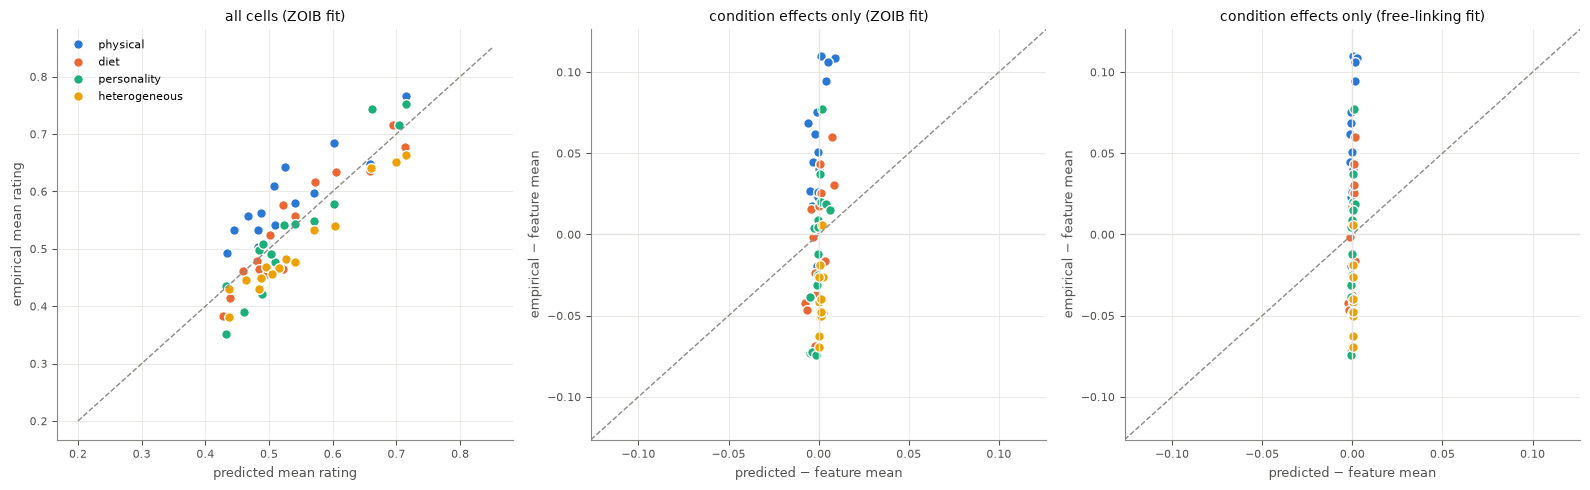

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
ax = axes[0]
for i, c in enumerate(CONDS):
    ax.plot(Pz[i], E[i], 'o', color=COND_COLOR[c], ms=7, mec='white', mew=1, label=c)
ax.plot([0.2, 0.85], [0.2, 0.85], color=MUTED, lw=1, ls='--')
ax.set_xlabel('predicted mean rating'); ax.set_ylabel('empirical mean rating')
ax.set_title('all cells (ZOIB fit)', color=TEXT_1); grid_xy(ax); ax.legend(loc='upper left')
for ax, (P, lab) in zip(axes[1:], [(Pz, 'ZOIB fit'), (Po, 'free-linking fit')]):
    Pw, Ew = P - P.mean(0), E - E.mean(0)
    for i, c in enumerate(CONDS):
        ax.plot(Pw[i], Ew[i], 'o', color=COND_COLOR[c], ms=7, mec='white', mew=1)
    lim = max(np.abs(Ew).max(), np.abs(Pw).max()) * 1.15
    ax.plot([-lim, lim], [-lim, lim], color=MUTED, lw=1, ls='--')
    ax.axhline(0, color=GRID, lw=1); ax.axvline(0, color=GRID, lw=1)
    ax.set_xlim(-lim, lim); ax.set_ylim(-lim, lim)
    ax.set_xlabel('predicted − feature mean'); ax.set_ylabel('empirical − feature mean')
    ax.set_title(f'condition effects only ({lab})', color=TEXT_1); grid_xy(ax)
fig.tight_layout(); plt.show()

Per feature: empirical vs predicted mean in each condition. Each feature's condition differences are
what the coherence field has to produce.

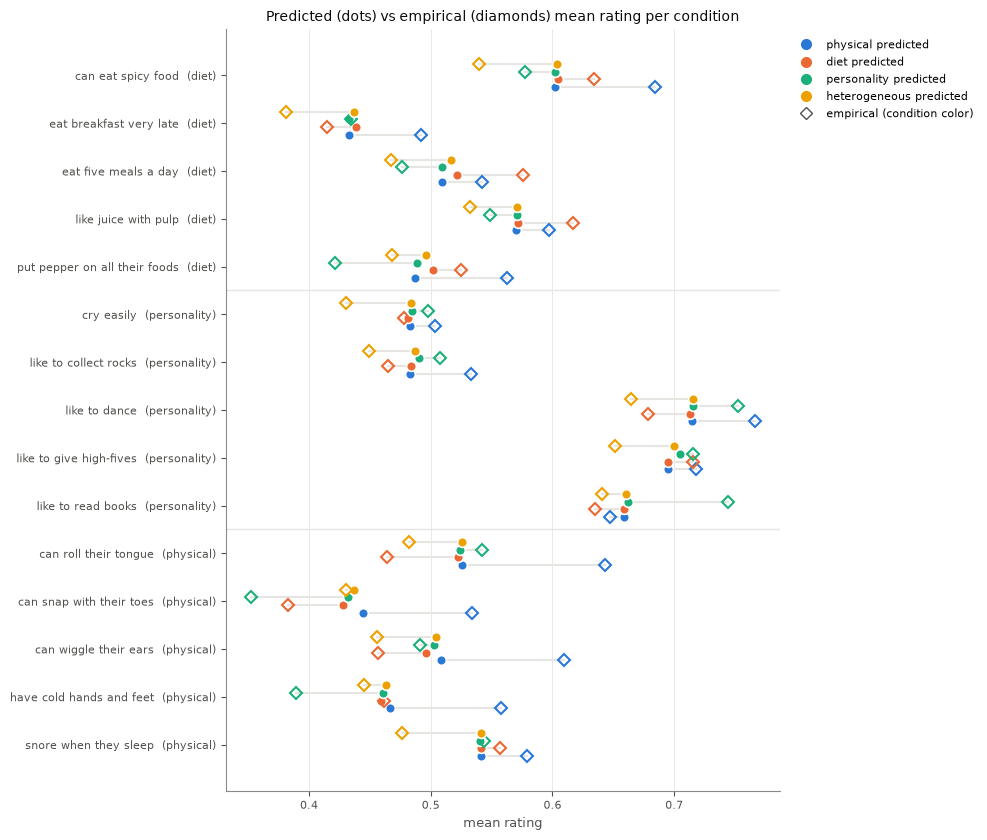

In [6]:
order = [j for t in TRAITS for j in range(J) if trait[j] == t][::-1]
fig, ax = plt.subplots(figsize=(10, 8.5))
for y, j in enumerate(order):
    for k, c in enumerate(CONDS):
        dy = (k - 1.5) * 0.16
        ax.plot([Pz[k, j], E[k, j]], [y + dy] * 2, color=GRID, lw=1.5, zorder=1)
        ax.plot(Pz[k, j], y + dy, 'o', color=COND_COLOR[c], ms=7, mec='white', mew=1.2, zorder=3)
        ax.plot(E[k, j], y + dy, 'D', mfc='none', mec=COND_COLOR[c], ms=6.5, mew=1.5, zorder=3)
ax.set_yticks(range(J)); ax.set_yticklabels([f"{features[j]}  ({trait[j]})" for j in order])
for b in (4.5, 9.5):
    ax.axhline(b, color=GRID, lw=1)
ax.set_xlabel('mean rating'); ax.grid(axis='x', color=GRID, lw=0.6); ax.set_axisbelow(True)
leg = [Line2D([], [], marker='o', ls='', color=COND_COLOR[c], ms=7, label=f'{c} predicted') for c in CONDS]
leg += [Line2D([], [], marker='D', ls='', mfc='none', mec=TEXT_2, ms=6.5, label='empirical (condition color)')]
ax.legend(handles=leg, loc='upper left', bbox_to_anchor=(1.01, 1))
ax.set_title('Predicted (dots) vs empirical (diamonds) mean rating per condition', color=TEXT_1)
fig.tight_layout(); plt.show()

## 3. The coherence field

Ratings-free coherence P(kind-linked) over the 2d embedding at the posterior-median θ, per condition
(`inference.gp_coherence_field`). Contours share **one color scale across the four conditions** so their
strength can be compared. Dark squares = that condition's training features (heard as generics); circles =
the 15 test features, filled by their **empirical mean rating on a separate scale** (right-hand colorbar)
and labeled.

In [7]:
# compute the coherence field once (slow-ish: ~5 s); re-run only if theta or the grid changes
all_x = np.vstack([np.array(geom['x_test'])] + [np.array(geom['x_train_cond'][c]) for c in CONDS])
pad = 0.08
(x_lo, y_lo), (x_hi, y_hi) = all_x.min(0) - pad, all_x.max(0) + pad
gx, gy = np.meshgrid(np.linspace(x_lo, x_hi, 90), np.linspace(y_lo, y_hi, 90))
X_grid = np.column_stack([gx.ravel(), gy.ravel()])
x_test = np.array(geom['x_test'])
FIELD = {c: inf.gp_coherence_field(geom, c, LS, MU, SIG, X_grid, beta_speaker=BETA).reshape(gx.shape) for c in CONDS}
vmin, vmax = min(f.min() for f in FIELD.values()), max(f.max() for f in FIELD.values())
emin, emax = min(e.min() for e in emp.values()), max(e.max() for e in emp.values())
print(f"field range across conditions: {vmin:.3f}-{vmax:.3f}")


field range across conditions: 0.787-0.845


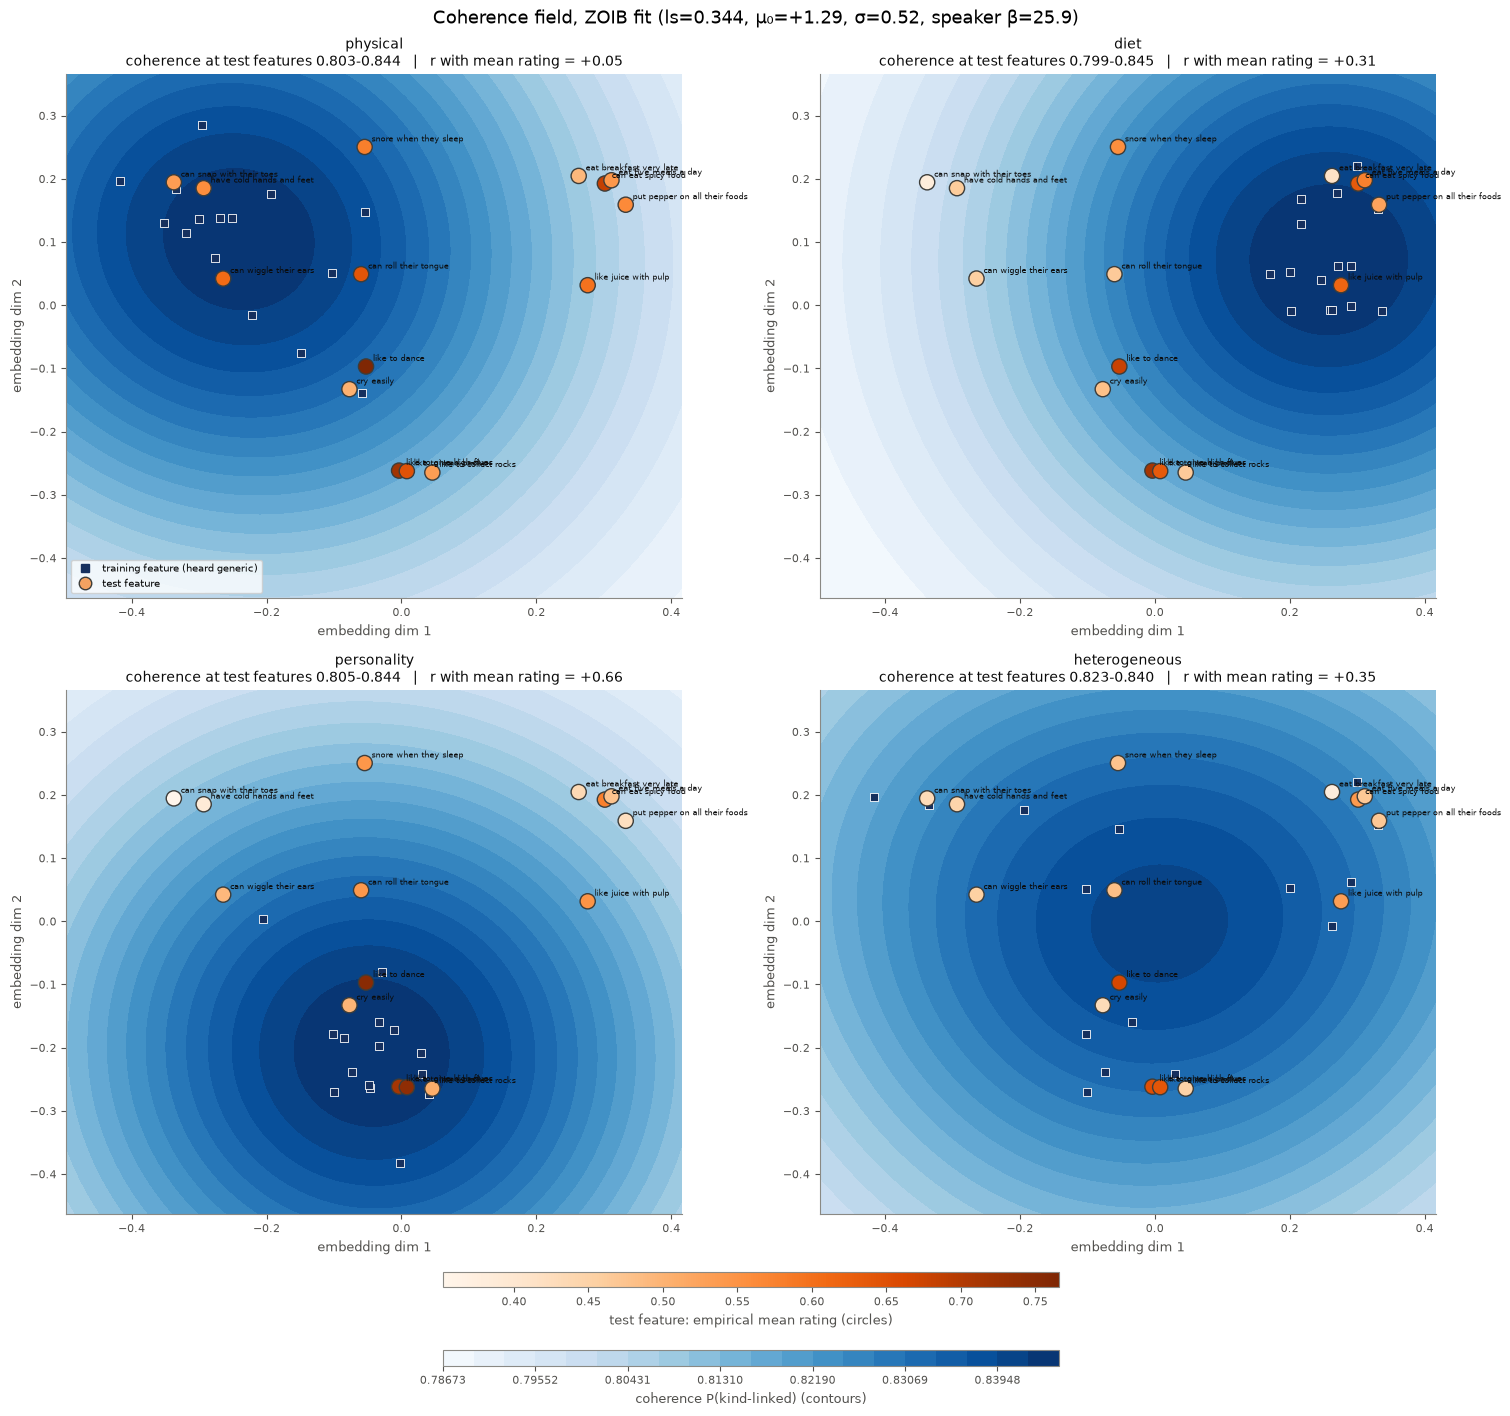

In [7]:
# plot the coherence field: iterate on aesthetics here (instant; uses FIELD, vmin/vmax, emin/emax from above)
fig, axes = plt.subplots(2, 2, figsize=(15, 14), layout='constrained')
for ax, c in zip(axes.ravel(), CONDS):
    cs = ax.contourf(gx, gy, FIELD[c], levels=np.linspace(vmin, vmax, 21), cmap='Blues')
    x_tr = np.array(geom['x_train_cond'][c])
    ax.scatter(x_tr[:, 0], x_tr[:, 1], s=36, marker='s', color='#16305e', edgecolor='white', lw=0.6, zorder=3)
    sc = ax.scatter(x_test[:, 0], x_test[:, 1], s=120, c=emp[c], cmap='Oranges', vmin=emin, vmax=emax,
                    edgecolor='#3d3d3a', lw=1, zorder=4)
    for (xx, yy), nm in zip(x_test, features):
        ax.annotate(nm, (xx, yy), fontsize=6, xytext=(5, 4), textcoords='offset points', color=TEXT_1, zorder=5)
    r = np.corrcoef(pz1[c], emp[c])[0, 1]
    ax.set_title(f"{c}\ncoherence at test features {pz1[c].min():.3f}-{pz1[c].max():.3f}   |   r with mean rating = {r:+.2f}",
                 color=TEXT_1, fontsize=10)
    ax.set_xlabel('embedding dim 1'); ax.set_ylabel('embedding dim 2')
fig.colorbar(cs, ax=axes, location='bottom', shrink=0.45, aspect=40, pad=0.02, label='coherence P(kind-linked) (contours)')
fig.colorbar(sc, ax=axes, location='bottom', shrink=0.45, aspect=40, pad=0.01, label='test feature: empirical mean rating (circles)')
axes[0, 0].legend(handles=[Line2D([], [], marker='s', ls='', color='#16305e', ms=6, label='training feature (heard generic)'),
                           Line2D([], [], marker='o', ls='', mfc='#f4a261', mec='#3d3d3a', ms=9, label='test feature')],
                  loc='lower left', fontsize=7, frameon=True)
fig.suptitle(f"Coherence field, ZOIB fit (ls={LS:.3f}, μ₀={MU:+.2f}, σ={SIG:.2f}, speaker β={BETA:.1f})", fontsize=13)
plt.show()

The same field along the axis that matters: coherence at each test feature (x) vs its empirical mean
rating (y), per condition. A positive slope within a condition means the field ranks features the way people
do.

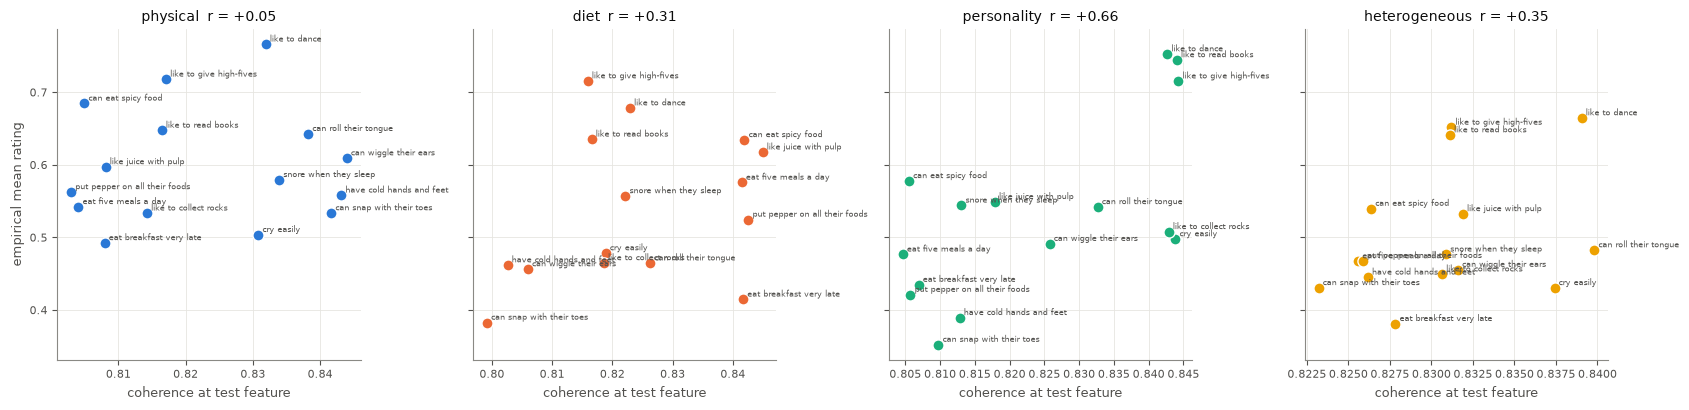

In [8]:
fig, axes = plt.subplots(1, 4, figsize=(17, 4.2), sharey=True)
for ax, c in zip(axes, CONDS):
    ax.plot(pz1[c], emp[c], 'o', color=COND_COLOR[c], ms=8, mec='white')
    for j in range(J):
        ax.annotate(features[j], (pz1[c][j], emp[c][j]), fontsize=5.5, xytext=(3, 2), textcoords='offset points', color=TEXT_2)
    ax.set_title(f"{c}  r = {np.corrcoef(pz1[c], emp[c])[0, 1]:+.2f}", color=TEXT_1)
    ax.set_xlabel('coherence at test feature'); grid_xy(ax)
axes[0].set_ylabel('empirical mean rating')
fig.tight_layout(); plt.show()

## 4. The linking components of each feature

Each feature's two components, unmixed. Curve = the Beta part scaled by the share of answers it covers,
(1 − P(0) − P(100))·Beta(r); dashed = component mean; corner text = its point masses. Grey = the feature's
pooled ratings excluding exact 0 and 100 (density, same scaling). Blue = kind-linked, orange = not kind-linked.

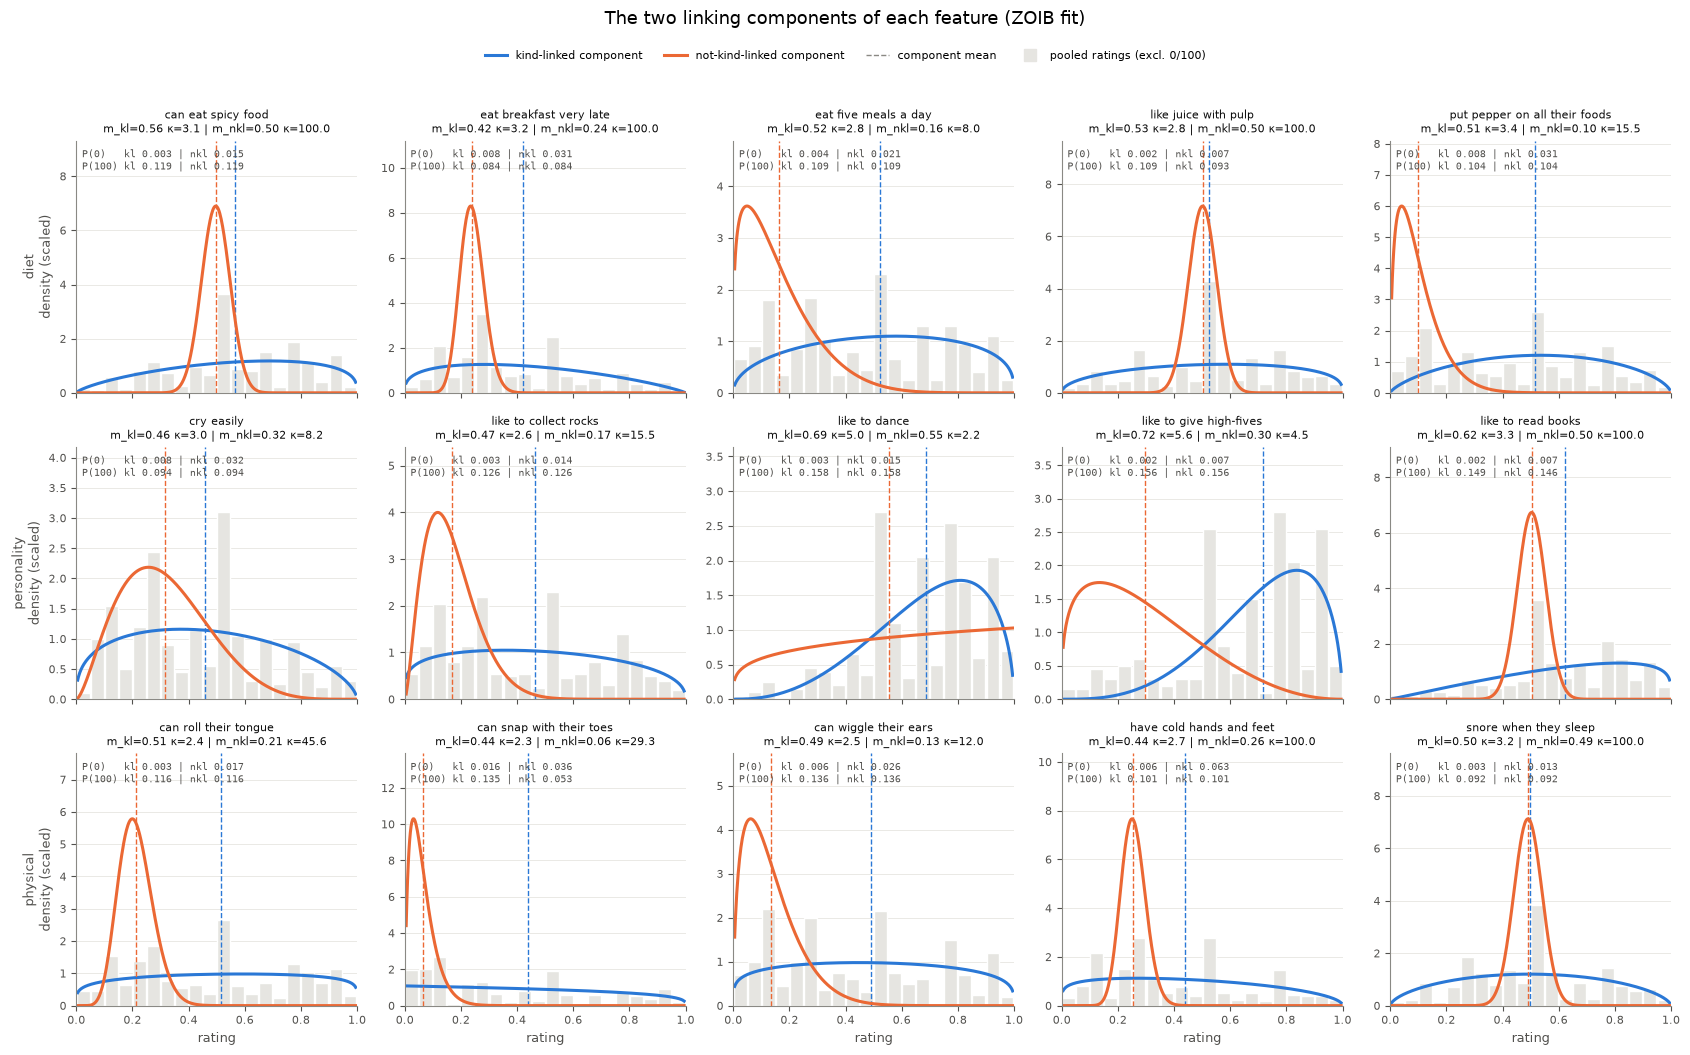

In [9]:
XG = np.linspace(0.005, 0.995, 400)
HB = np.linspace(0, 1, 21)
Kall = np.concatenate([K[c] for c in CONDS])
fig, axes = plt.subplots(3, 5, figsize=(17, 10), sharex=True)
for r_i, t in enumerate(TRAITS):
    for k_i, j in enumerate([j for j in range(J) if trait[j] == t]):
        ax = axes[r_i, k_i]
        inter = Kall[:, j][(Kall[:, j] > 0) & (Kall[:, j] < 100)] / 100
        h, _ = np.histogram(inter, bins=HB, density=True)
        h = h * len(inter) / len(Kall[:, j])
        ax.bar(0.5 * (HB[1:] + HB[:-1]), h, width=0.046, color=GRID, edgecolor='white')
        top = h.max()
        for c in ('kl', 'nkl'):
            y = (1 - p['pi0_' + c][j] - p['pi1_' + c][j]) * sbeta.pdf(XG, p['a_' + c][j], p['b_' + c][j])
            ax.plot(XG, y, color=CLS_COLOR[c], lw=2.2)
            ax.axvline(p['m_' + c][j], color=CLS_COLOR[c], lw=1, ls='--')
            top = max(top, y.max())
        ax.set_ylim(0, 1.35 * top); ax.set_xlim(0, 1); grid_y(ax)
        ax.text(0.02, 0.97, f"P(0)   kl {p['pi0_kl'][j]:.3f} | nkl {p['pi0_nkl'][j]:.3f}\n"
                            f"P(100) kl {p['pi1_kl'][j]:.3f} | nkl {p['pi1_nkl'][j]:.3f}",
                transform=ax.transAxes, va='top', fontsize=7, color=TEXT_2, family='monospace')
        ax.set_title(f"{features[j]}\nm_kl={p['m_kl'][j]:.2f} κ={p['kappa_kl'][j]:.1f} | "
                     f"m_nkl={p['m_nkl'][j]:.2f} κ={p['kappa_nkl'][j]:.1f}", fontsize=8, color=TEXT_1)
    axes[r_i, 0].set_ylabel(f"{t}\ndensity (scaled)", color=TEXT_2)
for ax in axes[-1]:
    ax.set_xlabel('rating')
leg = [Line2D([], [], color=CLS_COLOR['kl'], lw=2.2, label='kind-linked component'),
       Line2D([], [], color=CLS_COLOR['nkl'], lw=2.2, label='not-kind-linked component'),
       Line2D([], [], color=MUTED, lw=1, ls='--', label='component mean'),
       Line2D([], [], marker='s', ls='', color=GRID, ms=9, label='pooled ratings (excl. 0/100)')]
fig.legend(handles=leg, loc='upper center', ncol=4, bbox_to_anchor=(0.5, 1.02))
fig.suptitle('The two linking components of each feature (ZOIB fit)', y=1.05, fontsize=13)
fig.tight_layout(); plt.show()

In [10]:
cols = ['m_kl', 'kappa_kl', 'pi0_kl', 'pi1_kl', 'm_nkl', 'kappa_nkl', 'pi0_nkl', 'pi1_nkl']
pd.DataFrame({'feature': features, 'trait': trait, **{k: p[k] for k in cols},
              'mean gap (m_kl − m_nkl)': p['m_kl'] - p['m_nkl'],
              'P(100) gap': p['pi1_kl'] - p['pi1_nkl']}).round(3)

,feature,trait,m_kl,kappa_kl,pi0_kl,pi1_kl,m_nkl,kappa_nkl,pi0_nkl,pi1_nkl,mean gap (m_kl − m_nkl),P(100) gap
0,can eat spicy food,diet,0.565,3.059,0.003,0.119,0.497,100.000,0.015,0.119,0.068,0.000
1,eat breakfast very late,diet,0.420,3.169,0.008,0.084,0.240,100.000,0.031,0.084,0.180,0.000
2,eat five meals a day,diet,0.523,2.828,0.004,0.109,0.162,7.995,0.021,0.109,0.361,0.000
3,like juice with pulp,diet,0.525,2.805,0.002,0.109,0.502,100.000,0.007,0.093,0.024,0.017
4,put pepper on all their foods,diet,0.514,3.350,0.008,0.104,0.100,15.538,0.031,0.104,0.414,0.000
5,cry easily,personality,0.458,2.983,0.008,0.094,0.316,8.226,0.032,0.094,0.142,0.000
6,like to collect rocks,personality,0.465,2.650,0.003,0.126,0.167,15.544,0.014,0.126,0.299,0.000
7,like to dance,personality,0.687,5.040,0.003,0.158,0.554,2.243,0.015,0.158,0.132,0.000
8,like to give high-fives,personality,0.717,5.621,0.002,0.156,0.296,4.521,0.007,0.156,0.421,0.000
9,like to read books,personality,0.623,3.270,0.002,0.149,0.503,100.000,0.007,0.146,0.120,0.002


## 5. Per-condition mixtures against the data

For each feature and condition: that condition's ratings (bars, per slider value, 5-point bins, excluding
exact 0/100) against the mixture the model predicts from that condition's coherence (line), on a log scale.
Stems at 0 and 100: observed share (grey diamond) vs predicted point mass (colored dot). One figure per
trait.

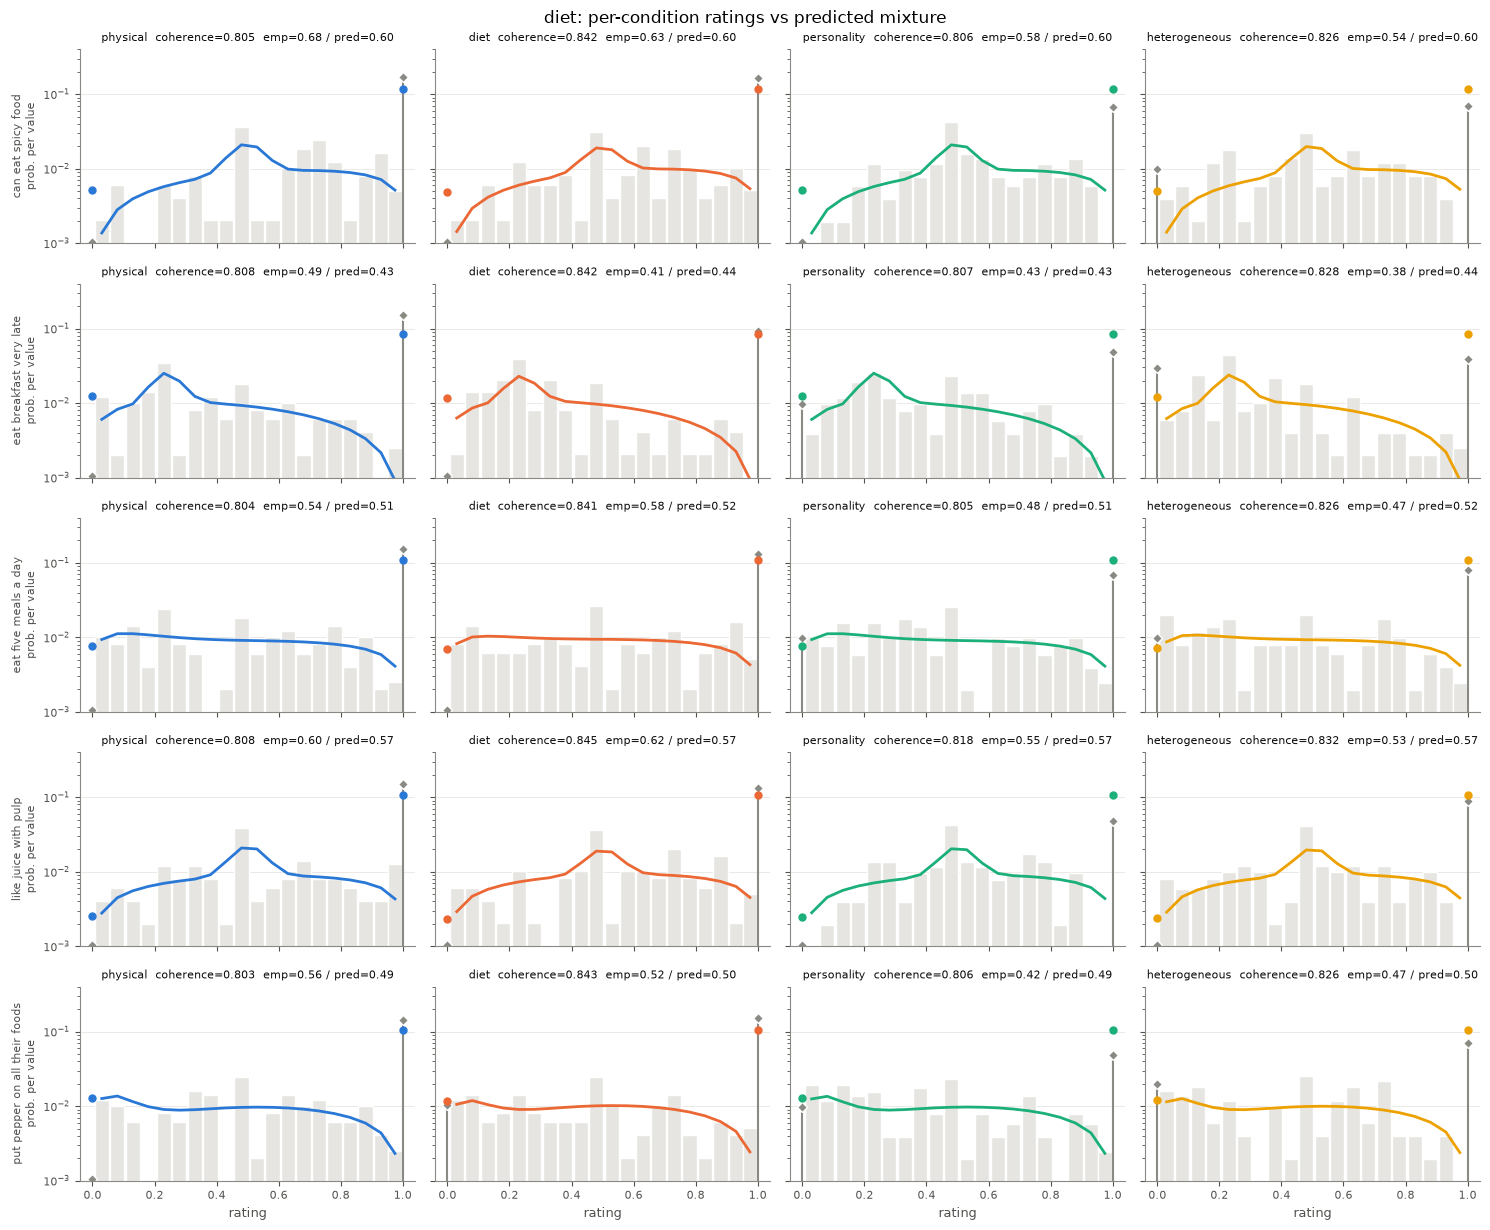

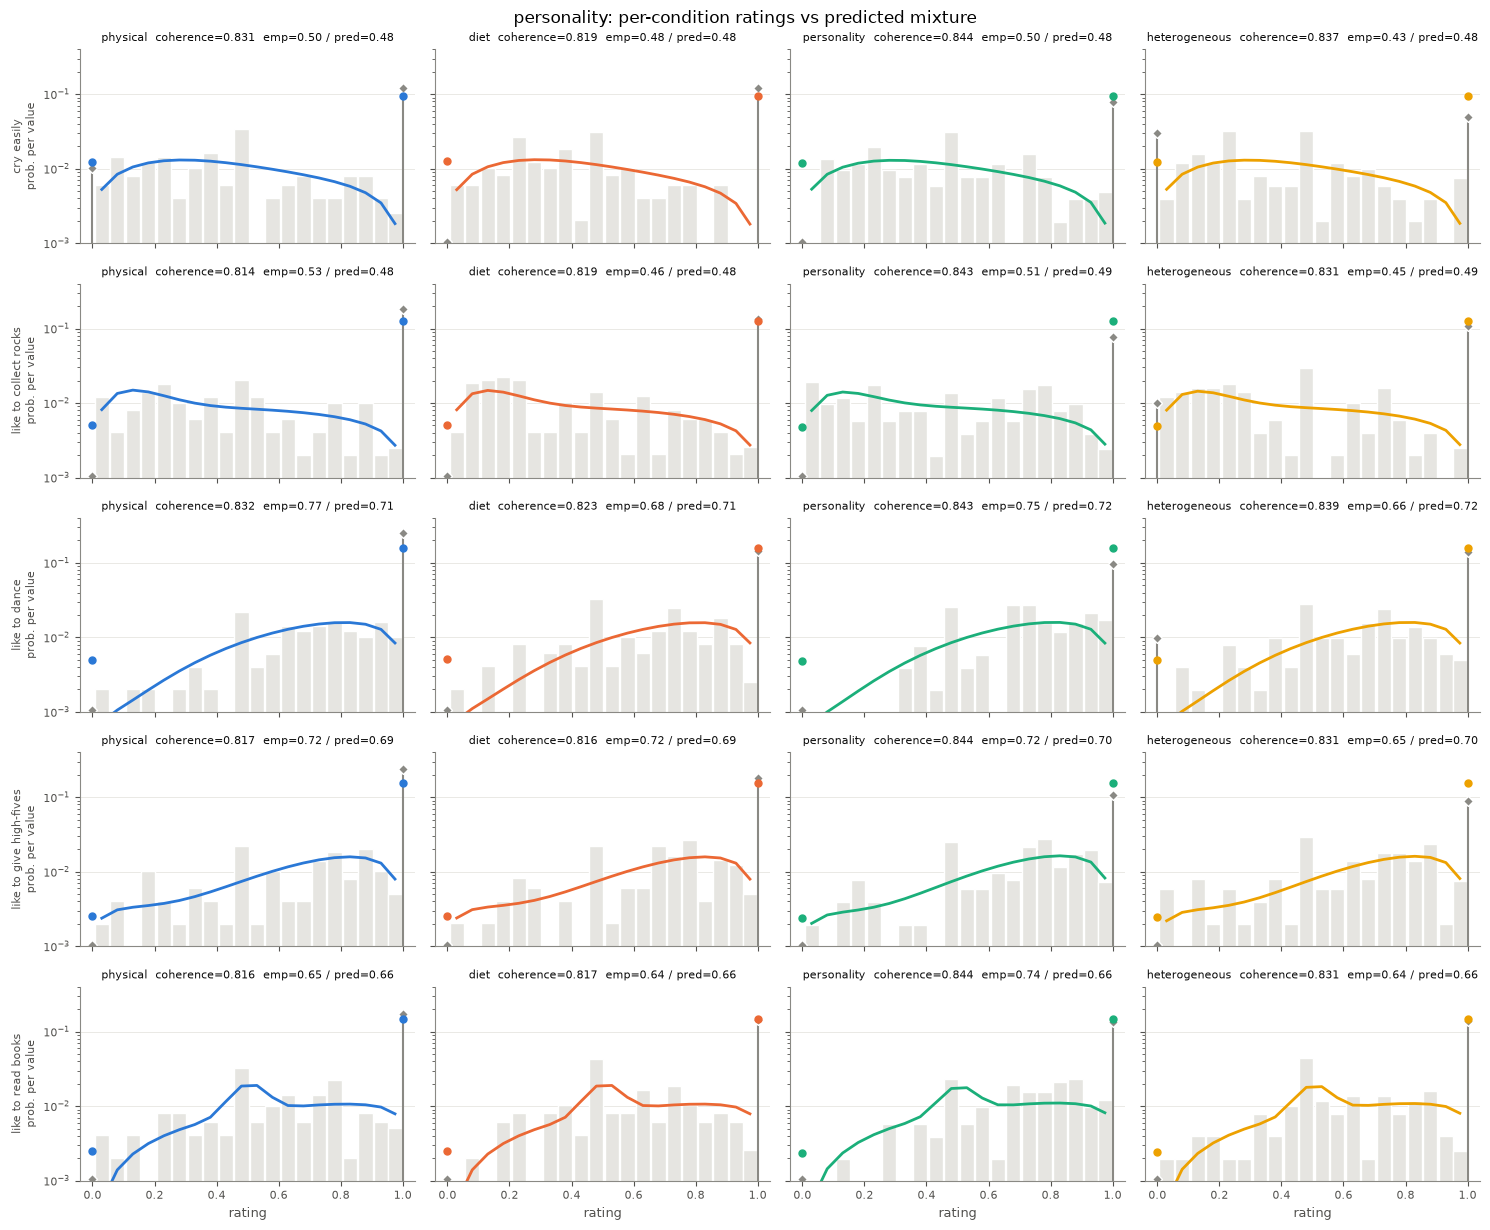

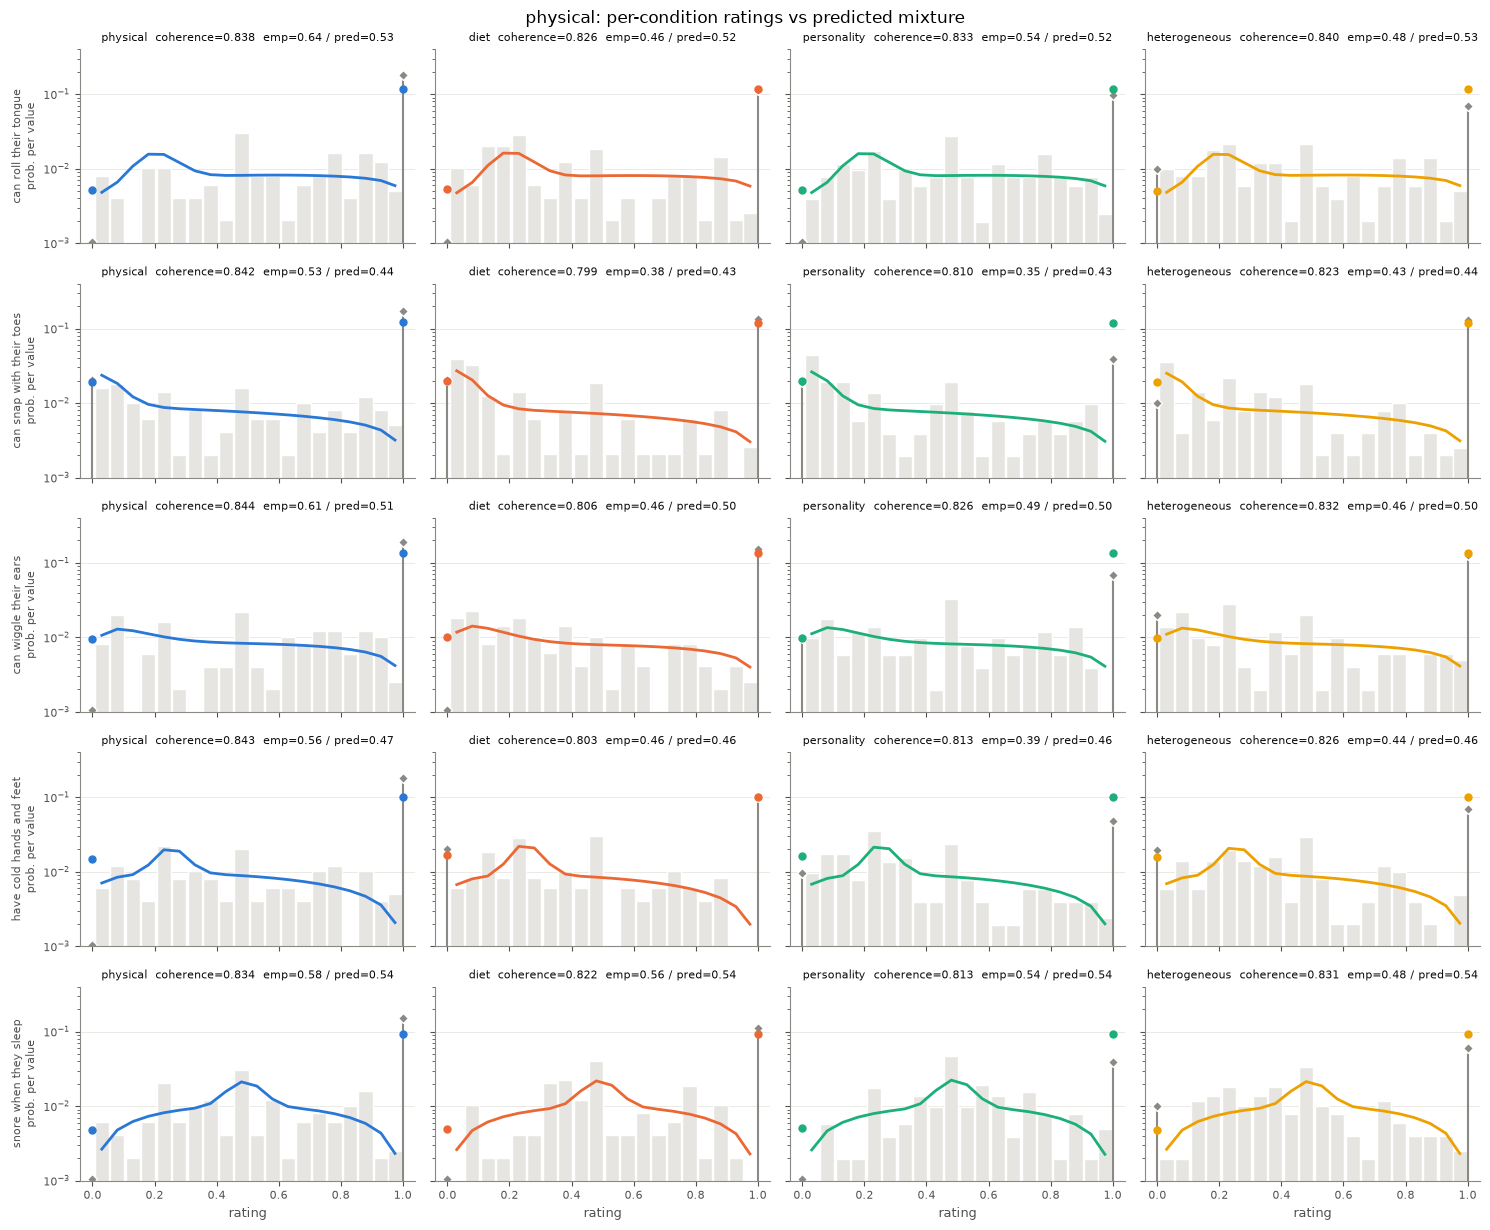

In [11]:
BINS = [np.arange(lo, min(lo + 5, 100)) for lo in np.arange(1, 101, 5)]
CEN = np.array([b.mean() / 100 for b in BINS])
def mix_per_value(j, w):
    comp = lambda c, x: (1 - p['pi0_' + c][j] - p['pi1_' + c][j]) * sbeta.pdf(x, p['a_' + c][j], p['b_' + c][j])
    return np.array([np.mean(w * comp('kl', b / 100) + (1 - w) * comp('nkl', b / 100)) * 0.01 for b in BINS])
for t in TRAITS:
    js = [j for j in range(J) if trait[j] == t]
    fig, axes = plt.subplots(len(js), 4, figsize=(15, 2.5 * len(js)), sharex=True, sharey=True)
    for r_i, j in enumerate(js):
        for k_i, c in enumerate(CONDS):
            ax = axes[r_i, k_i]
            kc = K[c][:, j]
            ax.bar(CEN, [np.isin(kc, b).mean() / len(b) for b in BINS], width=0.046, color=GRID, edgecolor='white')
            ax.plot(CEN, mix_per_value(j, pz1[c][j]), color=COND_COLOR[c], lw=2)
            for v, key in [(0, 'pi0'), (100, 'pi1')]:
                obs = np.mean(kc == v)
                ax.plot([v / 100] * 2, [1e-3, max(obs, 1e-3)], color=MUTED, lw=1.5)
                ax.plot(v / 100, max(obs, 1.05e-3), 'D', color=MUTED, ms=5.5, mec='white')
                ax.plot(v / 100, pz1[c][j] * p[key + '_kl'][j] + (1 - pz1[c][j]) * p[key + '_nkl'][j], 'o',
                        color=COND_COLOR[c], ms=5, zorder=4)
            ax.set_yscale('log'); ax.set_ylim(1e-3, 0.4); ax.set_xlim(-0.04, 1.04); grid_y(ax)
            ax.set_title(f"{c}  coherence={pz1[c][j]:.3f}  emp={emp[c][j]:.2f} / pred={Pz[k_i, j]:.2f}", fontsize=8, color=TEXT_1)
        axes[r_i, 0].set_ylabel(f"{features[j]}\nprob. per value", fontsize=8, color=TEXT_2)
    for ax in axes[-1]:
        ax.set_xlabel('rating')
    fig.suptitle(f"{t}: per-condition ratings vs predicted mixture", fontsize=12)
    fig.tight_layout(); plt.show()

## 6. What the linking fixes vs what coherence moves

For each feature the grey bar spans the two components' expected ratings, E[r | nkl] (○) to E[r | kl] (●),
including their point masses. Every predicted mean lies on that bar at
coherence·E[r | kl] + (1 − coherence)·E[r | nkl]: the **bar's position** is set by the linking function and
**where along it** each condition lands is set by the coherence field.

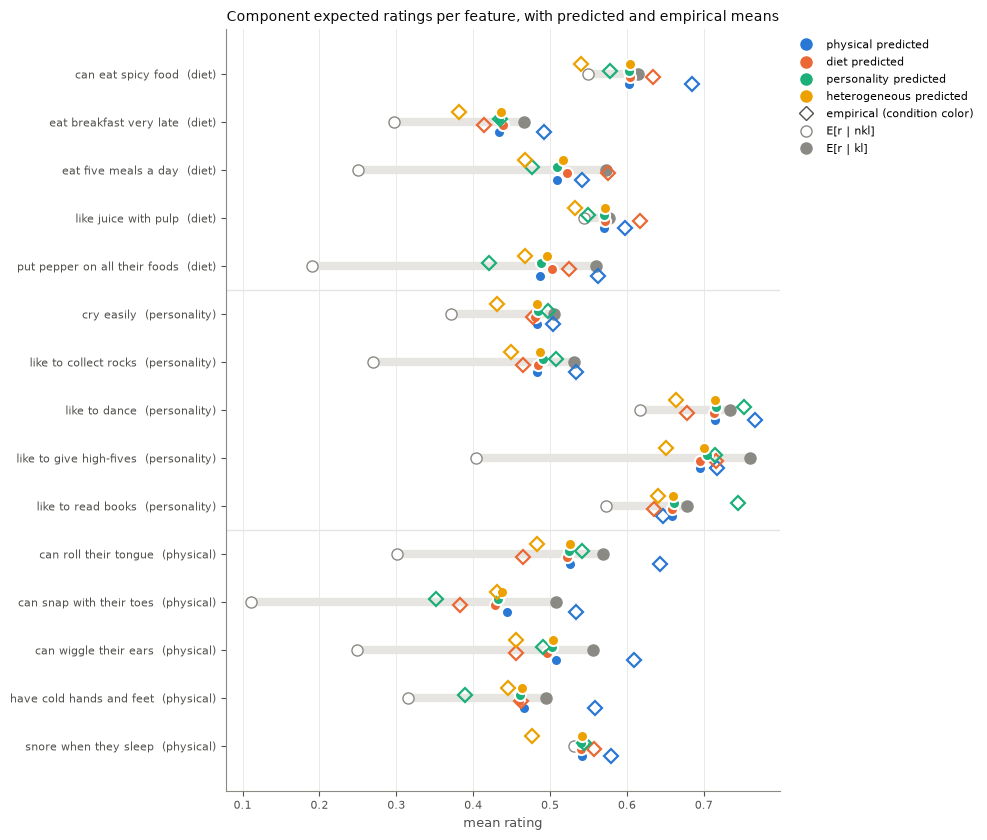

In [12]:
e_kl = p['pi1_kl'] + (1 - p['pi0_kl'] - p['pi1_kl']) * p['m_kl']
e_nkl = p['pi1_nkl'] + (1 - p['pi0_nkl'] - p['pi1_nkl']) * p['m_nkl']
fig, ax = plt.subplots(figsize=(10, 8.5))
for y, j in enumerate(order):
    ax.plot([e_nkl[j], e_kl[j]], [y, y], color=GRID, lw=6, solid_capstyle='round', zorder=1)
    ax.plot(e_nkl[j], y, 'o', mfc='white', mec=MUTED, ms=8, zorder=2)
    ax.plot(e_kl[j], y, 'o', color=MUTED, ms=8, zorder=2)
    for k, c in enumerate(CONDS):
        dy = (k - 1.5) * 0.14
        ax.plot(Pz[k, j], y + dy, 'o', color=COND_COLOR[c], ms=8, mec='white', mew=1.5, zorder=3)
        ax.plot(E[k, j], y + dy, 'D', mfc='none', mec=COND_COLOR[c], ms=7, mew=1.6, zorder=3)
ax.set_yticks(range(J)); ax.set_yticklabels([f"{features[j]}  ({trait[j]})" for j in order])
for b in (4.5, 9.5):
    ax.axhline(b, color=GRID, lw=1)
ax.set_xlabel('mean rating'); ax.grid(axis='x', color=GRID, lw=0.6); ax.set_axisbelow(True)
leg = [Line2D([], [], marker='o', ls='', color=COND_COLOR[c], ms=8, label=f'{c} predicted') for c in CONDS]
leg += [Line2D([], [], marker='D', ls='', mfc='none', mec=TEXT_2, ms=7, label='empirical (condition color)'),
        Line2D([], [], marker='o', ls='', mfc='white', mec=MUTED, ms=8, label='E[r | nkl]'),
        Line2D([], [], marker='o', ls='', color=MUTED, ms=8, label='E[r | kl]')]
ax.legend(handles=leg, loc='upper left', bbox_to_anchor=(1.01, 1))
ax.set_title('Component expected ratings per feature, with predicted and empirical means', color=TEXT_1)
fig.tight_layout(); plt.show()